In [37]:
import pandas as pd
import joblib as jb

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [28]:
wine = pd.read_csv("../../Data/interim/wine_cleaned.csv")

print(wine.shape)
print(wine.head())
print(wine.columns.tolist())

(178, 13)
   Alcohol  Malic_Acid   Ash  Alcalinity_of_Ash  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43               15.6        127           2.80   
1    13.20        1.78  2.14               11.2        100           2.65   
2    13.16        2.36  2.67               18.6        101           2.80   
3    14.37        1.95  2.50               16.8        113           3.85   
4    13.24        2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280_OD315  Proline  
0         3.92     1065  


In [29]:
if "Class" in wine.columns:
    original_classes = wine["Class"]
    X = wine.drop(columns=["Class"])
else:
    X = wine.copy()

In [30]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

jb.dump(scaler, "scaler.pkl")

print("Scaler fitted and saved successfully!")
print("Scaled data shape:", X_scaled.shape)

Scaler fitted and saved successfully!
Scaled data shape: (178, 13)


In [31]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

print("K-Means training completed!")
print("Cluster centers shape:", kmeans.cluster_centers_.shape)

K-Means training completed!
Cluster centers shape: (3, 13)


c:\Users\veere\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [32]:
wine_clustered = X.copy()
wine_clustered["Cluster"] = kmeans.labels_

print(wine_clustered.head())

print("\nSamples in each cluster:")
print(wine_clustered["Cluster"].value_counts().sort_index())

   Alcohol  Malic_Acid   Ash  Alcalinity_of_Ash  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43               15.6        127           2.80   
1    13.20        1.78  2.14               11.2        100           2.65   
2    13.16        2.36  2.67               18.6        101           2.80   
3    14.37        1.95  2.50               16.8        113           3.85   
4    13.24        2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280_OD315  Proline  Cluster  
0         3.92     1065    

In [33]:
jb.dump(kmeans, "kmeans_model.pkl")

print("K-Means model saved successfully!")

K-Means model saved successfully!


In [35]:
cluster_counts = pd.Series(
    kmeans.labels_,
    name="Cluster"
).value_counts().sort_index()

print(cluster_counts)

Cluster
0    65
1    51
2    62
Name: count, dtype: int64


In [36]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, kmeans.labels_)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.2849


In [39]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("PCA data shape:", X_pca.shape)

Original data shape: (178, 13)
PCA data shape: (178, 2)


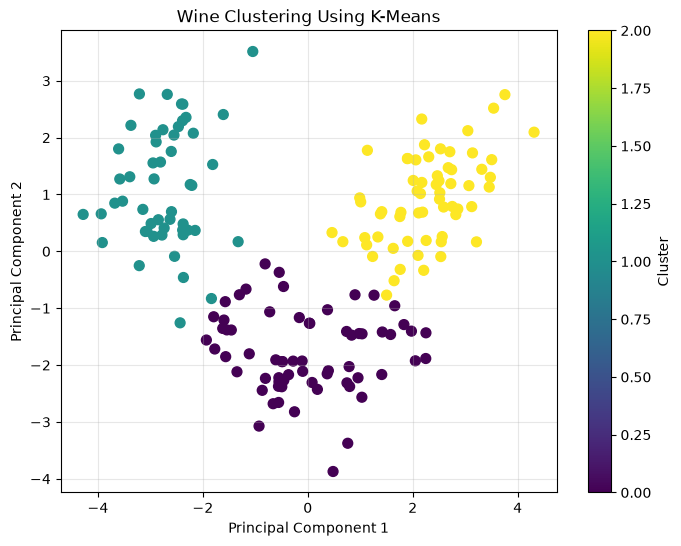

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans.labels_,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Clustering Using K-Means")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)

plt.show()

In [43]:
results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia = model.inertia_
    silhouette = silhouette_score(X_scaled, labels)

    results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

c:\Users\veere\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\veere\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\veere\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\veere\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

    K    Inertia  Silhouette Score
0   2  1658.7589            0.2593
1   3  1277.9285            0.2849
2   4  1175.4283            0.2602
3   5  1109.5127            0.2016
4   6  1046.0023            0.2372
5   7   981.5952            0.2036
6   8   935.2012            0.1570
7   9   889.8929            0.1499
8  10   845.8952            0.1436


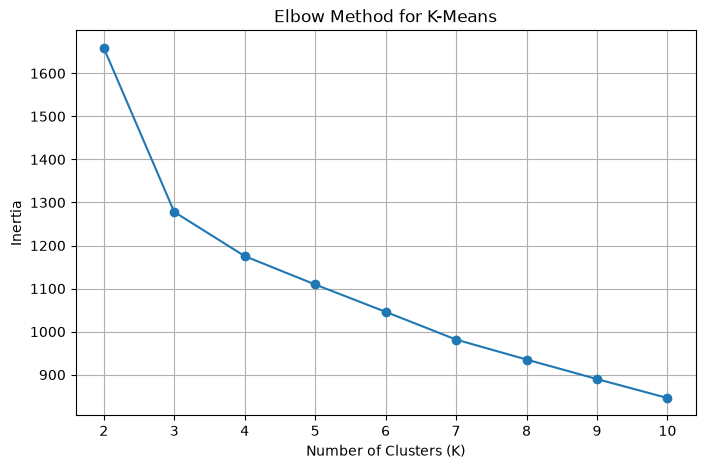

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

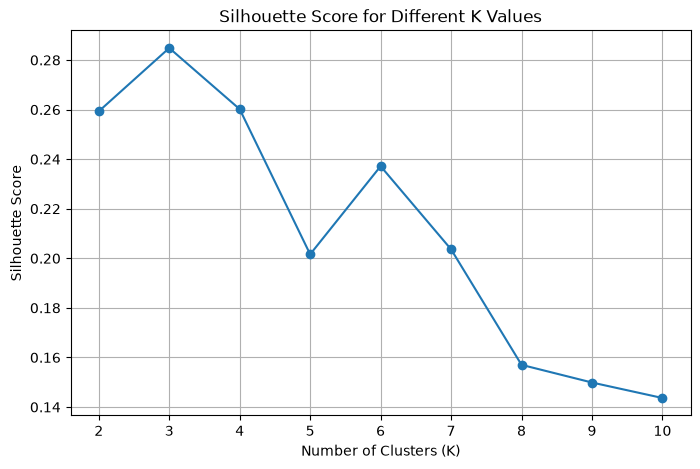

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [46]:
# Select one sample containing the 13 original features
sample = X.iloc[[0]]

# Scale the sample using the existing fitted scaler
sample_scaled = scaler.transform(sample)

# Predict its cluster
predicted_cluster = kmeans.predict(sample_scaled)

print("Predicted Cluster:", predicted_cluster[0])

Predicted Cluster: 2


In [47]:
original_prediction = kmeans.predict(X_scaled[:5])

loaded_prediction = kmeans.predict(
    scaler.transform(X.iloc[:5])
)

print("Original predictions:", original_prediction)
print("Loaded predictions:  ", loaded_prediction)

print(
    "Predictions match:",
    (original_prediction == loaded_prediction).all()
)

Original predictions: [2 2 2 2 2]
Loaded predictions:   [2 2 2 2 2]
Predictions match: True
